# MSE 5951 Lab 4 Galvanic Corrosion: figure code

### Figure Generation Guide
* **Code Cell 1 (after file uploads)**: Parses the Gamry headers and outputs raw data columns and area values.
* **Code Cell 2**: Generates **Exercise 1** (Fe Anodic Curve, Part 6) -> `example_1_fe_anodic.png`
* **Code Cell 3**: Generates **Exercise 2** (Pt Sheet Cathodic Overlay, 7a & 7b) -> `example_2_pt_overlay.png`
* **Code Cell 4**: Generates **Exercise 3** (Pt Open Circuit Potential, Part 8) -> `example_3_pt_eoc.png`
* **Code Cell 5**: Generates **Exercise 4** (Pt Sheet & Fe Overlay with Equal Areas Intersection) -> `example_4_crossing.png`
* **Code Cell 6**: Generates **Exercises 5 & 6** (Absolute Current Overlay & Mixed Potential Intersections for Sheet and Wire) -> `example_5_6_crossings.png`
* **Code Cell 7**: Generates **Parts 4 & 5 ZRA Analysis** (Galvanic Current and Couple Potential vs. Time) -> `zra_analysis.png`

> **Note:** Please ensure that all 6 required `.DTA` files are uploaded in the first file-upload code cell before executing the plotting code blocks.

In [2]:
from google.colab import files; up = files.upload()

Saving Lab4_Part8_Pt_Eoc_TA.DTA to Lab4_Part8_Pt_Eoc_TA.DTA
Saving Lab4_Part7b_PtSheet_TA.DTA to Lab4_Part7b_PtSheet_TA.DTA
Saving Lab4_Part7a_PtSheet_TA.DTA to Lab4_Part7a_PtSheet_TA.DTA
Saving Lab4_Part6_Fe_anodic_GroupA.DTA to Lab4_Part6_Fe_anodic_GroupA.DTA
Saving Lab4_Part5_ZRA_PtWire_GroupA.DTA to Lab4_Part5_ZRA_PtWire_GroupA.DTA
Saving Lab4_Part4_ZRA_PtSheet_GroupA.DTA to Lab4_Part4_ZRA_PtSheet_GroupA.DTA


In [4]:
import os
import re

def parse_gamry_header_area(file_path):
    """Parses a Gamry .DTA file to extract the sample AREA value from the header.

    Handles typical formats like 'AREA QUANT 1.0' or 'AREA VALUE 1.0' tab-delimited.
    """
    # We look for lines starting with AREA, followed by non-numeric labels, followed by a float value
    area_pattern = re.compile(r'^AREA\s+\w+\s+([\d\.\+\-E]+)', re.IGNORECASE)
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line_strip = line.strip()
            match = area_pattern.match(line_strip)
            if match:
                try:
                    return float(match.group(1))
                except ValueError:
                    pass
            # Fallback if it's just 'AREA' followed by a number directly
            elif line_strip.startswith('AREA'):
                parts = line_strip.split()
                for part in parts[1:]:
                    try:
                        return float(part)
                    except ValueError:
                        continue
    return None

def parse_gamry_columns(file_path):
    """Parses a Gamry .DTA file to extract the data table column names."""
    columns = []
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        lines = f.readlines()

    # Locate where the curve table starts
    for idx, line in enumerate(lines):
        if line.strip().startswith('CURVE'):
            # Typically, the column names are on the line following 'CURVE'
            if idx + 1 < len(lines):
                col_line = lines[idx + 1].strip()
                columns = col_line.split('\t')
            break
    return columns

# List of uploaded .DTA files to process
dta_files = [
    'Lab4_Part4_ZRA_PtSheet_GroupA.DTA',
    'Lab4_Part5_ZRA_PtWire_GroupA.DTA',
    'Lab4_Part6_Fe_anodic_GroupA.DTA',
    'Lab4_Part7a_PtSheet_TA.DTA',
    'Lab4_Part7b_PtSheet_TA.DTA',
    'Lab4_Part8_Pt_Eoc_TA.DTA'
]

for file_name in dta_files:
    file_path = os.path.join('/content', file_name)
    if os.path.exists(file_path):
        print(f"File: {file_name}")
        area = parse_gamry_header_area(file_path)
        cols = parse_gamry_columns(file_path)
        print(f"  AREA: {area}")
        print(f"  Columns: {cols}")
        print("-" * 50)
    else:
        print(f"File not found: {file_name}")


File: Lab4_Part4_ZRA_PtSheet_GroupA.DTA
  AREA: 1.0
  Columns: ['Pt', 'T', 'Vf', 'Im', 'Vu', 'Sig', 'Ach', 'IERange', 'Over', 'Temp']
--------------------------------------------------
File: Lab4_Part5_ZRA_PtWire_GroupA.DTA
  AREA: 1.0
  Columns: ['Pt', 'T', 'Vf', 'Im', 'Vu', 'Sig', 'Ach', 'IERange', 'Over', 'Temp']
--------------------------------------------------
File: Lab4_Part6_Fe_anodic_GroupA.DTA
  AREA: 0.503
  Columns: ['Pt', 'T', 'Vf', 'Im', 'Vu', 'Sig', 'Ach', 'IERange', 'Over', 'Temp']
--------------------------------------------------
File: Lab4_Part7a_PtSheet_TA.DTA
  AREA: 3.341
  Columns: ['Pt', 'T', 'Vf', 'Im', 'Vu', 'Sig', 'Ach', 'IERange', 'Over', 'Temp']
--------------------------------------------------
File: Lab4_Part7b_PtSheet_TA.DTA
  AREA: 3.341
  Columns: ['Pt', 'T', 'Vf', 'Im', 'Vu', 'Sig', 'Ach', 'IERange', 'Over', 'Temp']
--------------------------------------------------
File: Lab4_Part8_Pt_Eoc_TA.DTA
  AREA: 1.0
  Columns: ['Pt', 'T', 'Vf', 'Vm', 'Ach', '

<>:58: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1668/2313705608.py:58: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log(i / \mathrm{A \cdot cm^{-2}})$')


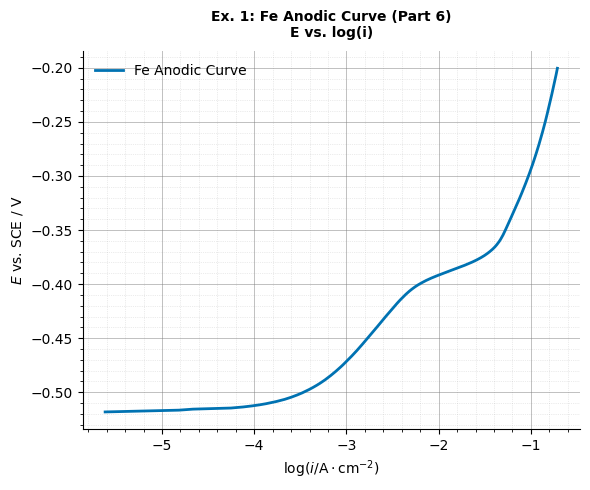

In [17]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def parse_dta_to_dataframe(file_path):
    """Parses a Gamry .DTA file and returns the data table as a pandas DataFrame, coercing invalid values to NaN."""
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        lines = f.readlines()

    start_idx = -1
    for idx, line in enumerate(lines):
        if line.strip().startswith('CURVE'):
            start_idx = idx + 2  # Skip 'CURVE' and the column headers line
            break

    if start_idx == -1 or start_idx >= len(lines):
        return pd.DataFrame()

    # Get the column names
    cols = lines[start_idx - 1].strip().split('	')

    # Read the data rows until the end of the block (or file)
    data_rows = []
    for line in lines[start_idx:]:
        stripped = line.strip()
        if not stripped or stripped.startswith('INDEX') or stripped.startswith('EXPERIMENT'):
            break
        parts = stripped.split('	')
        if len(parts) == len(cols):
            data_rows.append(parts)

    df = pd.DataFrame(data_rows, columns=cols)
    # Convert columns to numeric, coercing any characters like '#' or '..........' to NaN
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna(subset=['Vf'])
    return df

def plot_example_1():
    """Plots the Fe anodic curve (Part 6): E (V vs SCE) vs log i (current density, A/cm²) with a descriptive title."""
    file_path = '/content/Lab4_Part6_Fe_anodic_GroupA.DTA'
    area = parse_gamry_header_area(file_path)
    df = parse_dta_to_dataframe(file_path).dropna(subset=['Im'])

    # Im is current in Amperes, Vf is Potential vs Eref (V)
    current_density = np.abs(df['Im']) / area
    log_i = np.log10(current_density)
    E = df['Vf']

    fig, ax = plt.subplots(figsize=(6, 5))

    # Colorblind safe color (Okabe-Ito palette: Blue)
    ax.plot(log_i, E, color='#0072B2', linewidth=2, label='Fe Anodic Curve')

    ax.set_xlabel('$\log(i / \mathrm{A \cdot cm^{-2}})$')
    ax.set_ylabel('$E$ vs. SCE / V')
    ax.set_title("Ex. 1: Fe Anodic Curve (Part 6)\nE vs. log(i)", fontsize=10, fontweight='bold', pad=10)

    # Styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False)

    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    ax.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout()
    plt.savefig('example_1_fe_anodic.png', dpi=300)
    plt.show()

plot_example_1()

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1668/3387843009.py:21: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log(i / \mathrm{A \cdot cm^{-2}})$')


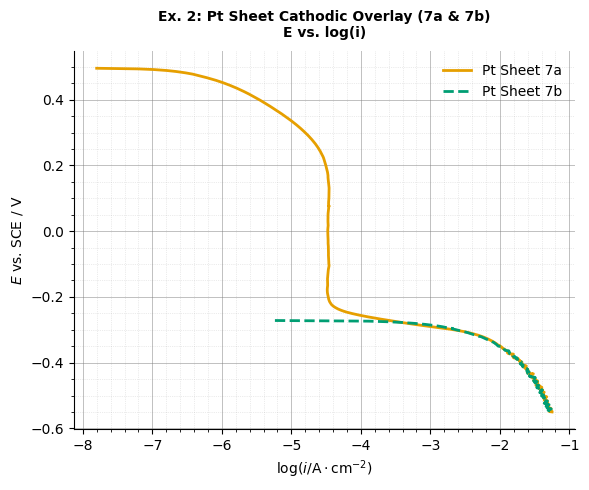

In [18]:
def plot_example_2():
    """Plots overlay of Pt 7a & 7b: E (V vs SCE) vs log i (current density, A/cm²) with a descriptive title."""
    file_7a = '/content/Lab4_Part7a_PtSheet_TA.DTA'
    file_7b = '/content/Lab4_Part7b_PtSheet_TA.DTA'

    area_7a = parse_gamry_header_area(file_7a)
    area_7b = parse_gamry_header_area(file_7b)

    df_7a = parse_dta_to_dataframe(file_7a).dropna(subset=['Im'])
    df_7b = parse_dta_to_dataframe(file_7b).dropna(subset=['Im'])

    log_i_7a = np.log10(np.abs(df_7a['Im']) / area_7a)
    log_i_7b = np.log10(np.abs(df_7b['Im']) / area_7b)

    fig, ax = plt.subplots(figsize=(6, 5))

    # Colorblind safe colors (Okabe-Ito: Orange and Bluish Green)
    ax.plot(log_i_7a, df_7a['Vf'], color='#E69F00', linewidth=2, label='Pt Sheet 7a')
    ax.plot(log_i_7b, df_7b['Vf'], color='#009E73', linewidth=2, linestyle='--', label='Pt Sheet 7b')

    ax.set_xlabel('$\log(i / \mathrm{A \cdot cm^{-2}})$')
    ax.set_ylabel('$E$ vs. SCE / V')
    ax.set_title("Ex. 2: Pt Sheet Cathodic Overlay (7a & 7b)\nE vs. log(i)", fontsize=10, fontweight='bold', pad=10)

    # Styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    ax.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout()
    plt.savefig('example_2_pt_overlay.png', dpi=300)
    plt.show()

plot_example_2()

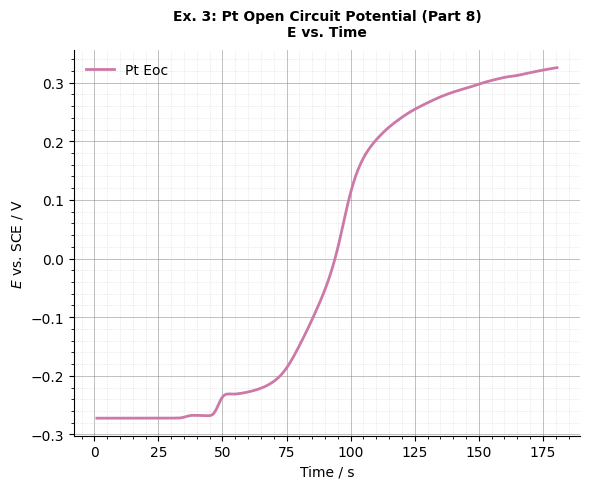

In [19]:
def plot_example_3():
    """Plots Pt Eoc (Part 8): E (V vs SCE) vs Time (s) with a descriptive title."""
    file_path = '/content/Lab4_Part8_Pt_Eoc_TA.DTA'
    df = parse_dta_to_dataframe(file_path).dropna(subset=['T'])

    # Time is in column 'T', Potential is in column 'Vf'
    time = df['T']
    E = df['Vf']

    fig, ax = plt.subplots(figsize=(6, 5))

    # Colorblind safe color (Okabe-Ito: Reddish purple)
    ax.plot(time, E, color='#CC79A7', linewidth=2, label='Pt Eoc')

    ax.set_xlabel('Time / s')
    ax.set_ylabel('$E$ vs. SCE / V')
    ax.set_title("Ex. 3: Pt Open Circuit Potential (Part 8)\nE vs. Time", fontsize=10, fontweight='bold', pad=10)

    # Styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    ax.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout()
    plt.savefig('example_3_pt_eoc.png', dpi=300)
    plt.show()

plot_example_3()

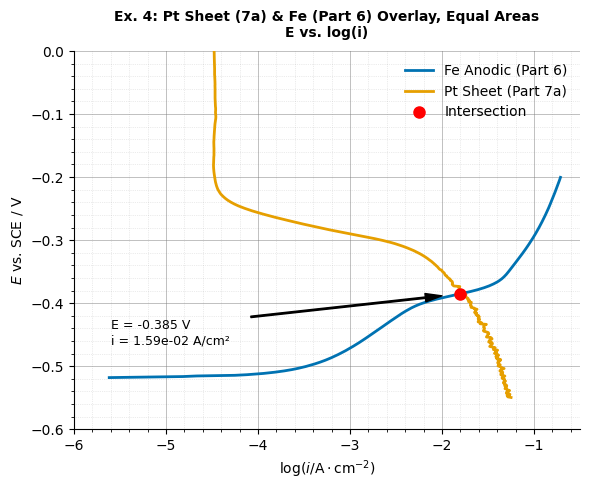

In [30]:
def plot_example_4():
    """Plots Pt 7a & Fe Part6 together as current density (A/cm²), finds and marks the intersection with a descriptive title."""
    file_fe = '/content/Lab4_Part6_Fe_anodic_GroupA.DTA'
    file_pt = '/content/Lab4_Part7a_PtSheet_TA.DTA'

    area_fe = parse_gamry_header_area(file_fe)
    area_pt = parse_gamry_header_area(file_pt)

    df_fe = parse_dta_to_dataframe(file_fe).dropna(subset=['Im'])
    df_pt = parse_dta_to_dataframe(file_pt).dropna(subset=['Im'])

    # Calculate log current density
    i_fe = np.abs(df_fe['Im']) / area_fe
    i_pt = np.abs(df_pt['Im']) / area_pt

    log_i_fe = np.log10(i_fe).values
    log_i_pt = np.log10(i_pt).values

    E_fe = df_fe['Vf'].values
    E_pt = df_pt['Vf'].values

    # Filter data to potential range [-0.9, 0]
    mask_fe = (E_fe >= -0.9) & (E_fe <= 0.0)
    mask_pt = (E_pt >= -0.9) & (E_pt <= 0.0)

    # Interpolate using log_i as the monotonic reference grid for the crossing region
    log_i_grid = np.linspace(-3.0, -1.0, 2000)
    E_fe_interp = np.interp(log_i_grid, log_i_fe[mask_fe][::-1] if log_i_fe[mask_fe][0] > log_i_fe[mask_fe][-1] else log_i_fe[mask_fe], E_fe[mask_fe][::-1] if log_i_fe[mask_fe][0] > log_i_fe[mask_fe][-1] else E_fe[mask_fe])
    E_pt_interp = np.interp(log_i_grid, log_i_pt[mask_pt][::-1] if log_i_pt[mask_pt][0] > log_i_pt[mask_pt][-1] else log_i_pt[mask_pt], E_pt[mask_pt][::-1] if log_i_pt[mask_pt][0] > log_i_pt[mask_pt][-1] else E_pt[mask_pt])

    # Find index where the potential difference is minimized
    idx = np.argmin(np.abs(E_fe_interp - E_pt_interp))
    cross_log_i = log_i_grid[idx]
    cross_E = E_fe_interp[idx]
    cross_i = 10**cross_log_i

    fig, ax = plt.subplots(figsize=(6, 5))

    # Colorblind safe colors (Okabe-Ito: Blue and Orange)
    ax.plot(log_i_fe, E_fe, color='#0072B2', linewidth=2, label='Fe Anodic (Part 6)')
    ax.plot(log_i_pt, E_pt, color='#E69F00', linewidth=2, label='Pt Sheet (Part 7a)')

    # Mark the crossing point
    ax.plot(cross_log_i, cross_E, 'ro', markersize=8, label='Intersection')
    ax.annotate(f'E = {cross_E:.3f} V\ni = {cross_i:.2e} A/cm²',
                xy=(cross_log_i, cross_E),
                xytext=(cross_log_i - 3.8, cross_E - 0.08),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
                fontsize=9)

    ax.set_xlabel(r'$\log(i / \mathrm{A \cdot cm^{-2}})$')
    ax.set_ylabel('$E$ vs. SCE / V')
    ax.set_ylim(-0.6, 0.0)
    ax.set_xlim(-6.0, -0.5)
    ax.set_title("Ex. 4: Pt Sheet (7a) & Fe (Part 6) Overlay, Equal Areas\nE vs. log(i)", fontsize=10, fontweight='bold', pad=10)

    # Styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False, loc='upper right')

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    ax.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout()
    plt.savefig('example_4_crossing.png', dpi=300)
    plt.show()

plot_example_4()

--- CORROSION CROSSING ANALYSIS ---
Fe vs. Pt Sheet Crossing (Scaled to 5.39 cm²):
  Potential (E): -0.327 V vs SCE
  Current (I): 3.53e-02 A
  Fe Current Density (i): 7.02e-02 A/cm²

Fe vs. Pt Wire Crossing (Scaled to 0.417 cm²):
  Potential (E): -0.386 V vs SCE
  Current (I): 7.32e-03 A
  Fe Current Density (i): 1.46e-02 A/cm²
------------------------------------


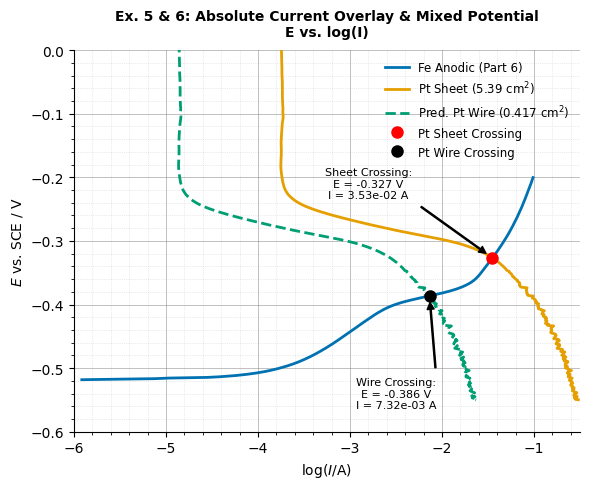

In [35]:
def plot_examples_5_6():
    """Plots absolute current for Pt sheet (scaled to handout area), predicted Pt wire,
    and Fe anodic curves, finds and marks the two crossings with Fe, with a descriptive title.
    """
    file_fe = '/content/Lab4_Part6_Fe_anodic_GroupA.DTA'
    file_pt = '/content/Lab4_Part7a_PtSheet_TA.DTA'

    # Handout areas (cm²)
    handout_pt_sheet_area = 5.39
    handout_pt_wire_area = 0.417
    handout_fe_area = 0.503

    # Header areas parsed from files
    header_fe_area = parse_gamry_header_area(file_fe) # 0.503
    header_pt_area = parse_gamry_header_area(file_pt) # 3.341

    df_fe = parse_dta_to_dataframe(file_fe).dropna(subset=['Im'])
    df_pt = parse_dta_to_dataframe(file_pt).dropna(subset=['Im'])

    # Absolute currents (I) in Amperes
    I_fe = np.abs(df_fe['Im']).values

    # Calculate Pt current density from experiment using its header area
    i_pt_density = np.abs(df_pt['Im']).values / header_pt_area

    # Scale absolute Pt currents to handout areas
    I_pt_sheet = i_pt_density * handout_pt_sheet_area
    I_pt_wire = i_pt_density * handout_pt_wire_area

    log_I_fe = np.log10(I_fe)
    log_I_pt_sheet = np.log10(I_pt_sheet)
    log_I_pt_wire = np.log10(I_pt_wire)

    E_fe = df_fe['Vf'].values
    E_pt = df_pt['Vf'].values

    # Filter to the potential range of interest [-0.9, 0]
    mask_fe = (E_fe >= -0.9) & (E_fe <= 0.0)
    mask_pt = (E_pt >= -0.9) & (E_pt <= 0.0)

    # Create a uniform log(I) grid for accurate interpolations
    log_I_grid = np.linspace(-6.0, -1.0, 3000)

    E_fe_interp = np.interp(
        log_I_grid,
        log_I_fe[mask_fe][::-1] if log_I_fe[mask_fe][0] > log_I_fe[mask_fe][-1] else log_I_fe[mask_fe],
        E_fe[mask_fe][::-1] if log_I_fe[mask_fe][0] > log_I_fe[mask_fe][-1] else E_fe[mask_fe]
    )
    E_pt_sheet_interp = np.interp(
        log_I_grid,
        log_I_pt_sheet[mask_pt][::-1] if log_I_pt_sheet[mask_pt][0] > log_I_pt_sheet[mask_pt][-1] else log_I_pt_sheet[mask_pt],
        E_pt[mask_pt][::-1] if log_I_pt_sheet[mask_pt][0] > log_I_pt_sheet[mask_pt][-1] else E_pt[mask_pt]
    )
    E_pt_wire_interp = np.interp(
        log_I_grid,
        log_I_pt_wire[mask_pt][::-1] if log_I_pt_wire[mask_pt][0] > log_I_pt_wire[mask_pt][-1] else log_I_pt_wire[mask_pt],
        E_pt[mask_pt][::-1] if log_I_pt_wire[mask_pt][0] > log_I_pt_wire[mask_pt][-1] else E_pt[mask_pt]
    )

    # Find crossings
    idx_sheet = np.argmin(np.abs(E_fe_interp - E_pt_sheet_interp))
    cross_log_I_sheet = log_I_grid[idx_sheet]
    cross_E_sheet = E_fe_interp[idx_sheet]
    cross_I_sheet = 10**cross_log_I_sheet

    idx_wire = np.argmin(np.abs(E_fe_interp - E_pt_wire_interp))
    cross_log_I_wire = log_I_grid[idx_wire]
    cross_E_wire = E_fe_interp[idx_wire]
    cross_I_wire = 10**cross_log_I_wire

    # Calculate Fe current densities at crossings (Fe Area = 0.503 cm²)
    cd_fe_sheet = cross_I_sheet / handout_fe_area
    cd_fe_wire = cross_I_wire / handout_fe_area

    # Print findings to terminal
    print("--- CORROSION CROSSING ANALYSIS ---")
    print(f"Fe vs. Pt Sheet Crossing (Scaled to {handout_pt_sheet_area} cm²):")
    print(f"  Potential (E): {cross_E_sheet:.3f} V vs SCE")
    print(f"  Current (I): {cross_I_sheet:.2e} A")
    print(f"  Fe Current Density (i): {cd_fe_sheet:.2e} A/cm²\n")
    print(f"Fe vs. Pt Wire Crossing (Scaled to {handout_pt_wire_area} cm²):")
    print(f"  Potential (E): {cross_E_wire:.3f} V vs SCE")
    print(f"  Current (I): {cross_I_wire:.2e} A")
    print(f"  Fe Current Density (i): {cd_fe_wire:.2e} A/cm²")
    print("------------------------------------")

    fig, ax = plt.subplots(figsize=(6, 5))

    # Colorblind friendly colors (Okabe-Ito: Blue, Orange, Bluish Green)
    ax.plot(log_I_fe, E_fe, color='#0072B2', linewidth=2, label='Fe Anodic (Part 6)')
    ax.plot(log_I_pt_sheet, E_pt, color='#E69F00', linewidth=2, label=f'Pt Sheet ({handout_pt_sheet_area} ' + r'$\mathrm{cm^2}$' + ')')
    ax.plot(log_I_pt_wire, E_pt, color='#009E73', linewidth=2, linestyle='--', label=f'Pred. Pt Wire ({handout_pt_wire_area} ' + r'$\mathrm{cm^2}$' + ')')

    # Mark the two crossings
    ax.plot(cross_log_I_sheet, cross_E_sheet, 'ro', markersize=8, label='Pt Sheet Crossing')
    ax.plot(cross_log_I_wire, cross_E_wire, 'ko', markersize=8, label='Pt Wire Crossing')

    # Annotations positioned precisely in the clean empty regions defined by the user
    # Sheet Crossing label: in the empty area just above the orange curve under the legend (centered around x=-2.8, E=-0.21)
    ax.annotate(f'Sheet Crossing:\nE = {cross_E_sheet:.3f} V\nI = {cross_I_sheet:.2e} A',
                xy=(cross_log_I_sheet, cross_E_sheet),
                xytext=(-2.8, -0.21),
                arrowprops=dict(facecolor='black', shrink=0.08, width=0.8, headwidth=5, headlength=5),
                fontsize=8, ha='center', va='center')

    # Wire Crossing label: in the bottom empty space under the curves (centered around x=-2.5, E=-0.54)
    ax.annotate(f'Wire Crossing:\nE = {cross_E_wire:.3f} V\nI = {cross_I_wire:.2e} A',
                xy=(cross_log_I_wire, cross_E_wire),
                xytext=(-2.5, -0.54),
                arrowprops=dict(facecolor='black', shrink=0.08, width=0.8, headwidth=5, headlength=5),
                fontsize=8, ha='center', va='center')

    ax.set_xlabel(r'$\log(I / \mathrm{A})$')
    ax.set_ylabel('$E$ vs. SCE / V')
    ax.set_ylim(-0.6, 0.0)
    ax.set_xlim(-6.0, -0.5)
    ax.set_title("Ex. 5 & 6: Absolute Current Overlay & Mixed Potential\nE vs. log(I)", fontsize=10, fontweight='bold', pad=10)

    # Styling
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False, loc='upper right', fontsize=8.5)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

    ax.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout()
    plt.savefig('example_5_6_crossings.png', dpi=300)
    plt.show()

plot_examples_5_6()

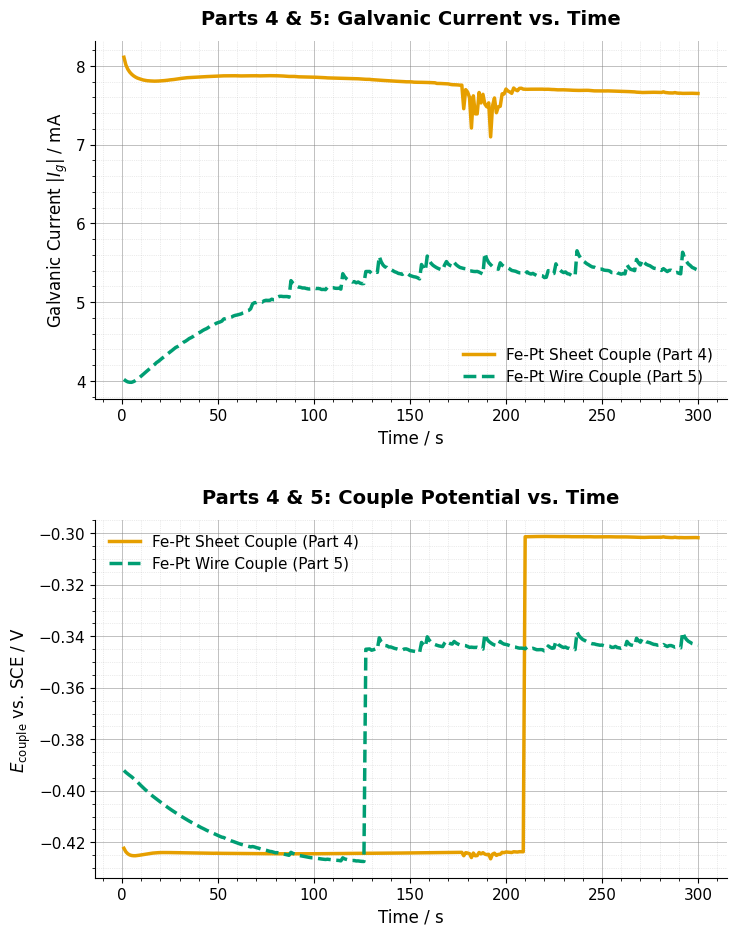

In [36]:
def plot_zra_data():
    """Plots galvanic current vs time and potential vs time for ZRA couples (Parts 4 & 5)
    stacked vertically with larger fonts and wider aspect ratios.
    """
    file_part4 = '/content/Lab4_Part4_ZRA_PtSheet_GroupA.DTA'
    file_part5 = '/content/Lab4_Part5_ZRA_PtWire_GroupA.DTA'

    df_part4 = parse_dta_to_dataframe(file_part4).dropna(subset=['T', 'Im', 'Vf'])
    df_part5 = parse_dta_to_dataframe(file_part5).dropna(subset=['T', 'Im', 'Vf'])

    # Setup two-panel plot stacked vertically (2 rows, 1 column)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

    # Colorblind friendly colors (Okabe-Ito: Orange and Bluish Green)
    color_sheet = '#E69F00'
    color_wire = '#009E73'

    # Panel 1: Galvanic Current (Im) vs Time
    ax1.plot(df_part4['T'], np.abs(df_part4['Im']) * 1e3, color=color_sheet, linewidth=2.5, label='Fe-Pt Sheet Couple (Part 4)')
    ax1.plot(df_part5['T'], np.abs(df_part5['Im']) * 1e3, color=color_wire, linewidth=2.5, linestyle='--', label='Fe-Pt Wire Couple (Part 5)')

    ax1.set_xlabel('Time / s', fontsize=12)
    ax1.set_ylabel('Galvanic Current $|I_g|$ / mA', fontsize=12)
    ax1.set_title("Parts 4 & 5: Galvanic Current vs. Time", fontsize=14, fontweight='bold', pad=12)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.legend(frameon=False, loc='best', fontsize=11)

    ax1.tick_params(axis='both', which='major', labelsize=11)
    ax1.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax1.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax1.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax1.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    # Panel 2: Couple Potential (Vf) vs Time
    ax2.plot(df_part4['T'], df_part4['Vf'], color=color_sheet, linewidth=2.5, label='Fe-Pt Sheet Couple (Part 4)')
    ax2.plot(df_part5['T'], df_part5['Vf'], color=color_wire, linewidth=2.5, linestyle='--', label='Fe-Pt Wire Couple (Part 5)')

    ax2.set_xlabel('Time / s', fontsize=12)
    ax2.set_ylabel('$E_{\\mathrm{couple}}$ vs. SCE / V', fontsize=12)
    ax2.set_title("Parts 4 & 5: Couple Potential vs. Time", fontsize=14, fontweight='bold', pad=12)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.legend(frameon=False, loc='best', fontsize=11)

    ax2.tick_params(axis='both', which='major', labelsize=11)
    ax2.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax2.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax2.grid(True, which='major', linestyle='-', linewidth=0.7, color='gray', alpha=0.5)
    ax2.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)

    plt.tight_layout(pad=3.0)
    plt.savefig('zra_analysis.png', dpi=300)
    plt.show()

plot_zra_data()

In [37]:
import glob; [files.download(f) for f in sorted(glob.glob("*.png"))]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[None, None, None, None, None, None]